In [56]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from src.config import calibrations_path,vendor_path,figures_path
from lmfit.models import Gaussian2dModel
import pandas as pd
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
file_name = 'spots_u'
img = np.load(f"{figures_path/'raw'/file_name}.npy")

In [ ]:
centrex = 1180
centrey = 230
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)]).T

In [91]:
results = []
for spot_location in spot_locations.T:
    target = img[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50]
    xdata = np.array([[i,j] for i in range(target.shape[0]) for j in range(target.shape[1])]).T
    model = Gaussian2dModel()
    params = model.guess(target.ravel(),xdata[0].ravel(),xdata[1].ravel())
    result = model.fit(target.ravel(),params,x = xdata[0].ravel(),y = xdata[1].ravel(),max_nfev = 10000)
    out_dict = result.params.valuesdict()
    out_dict['rsquared'] = result.rsquared
    results.append(out_dict)

In [93]:
pdf = pd.DataFrame(results)

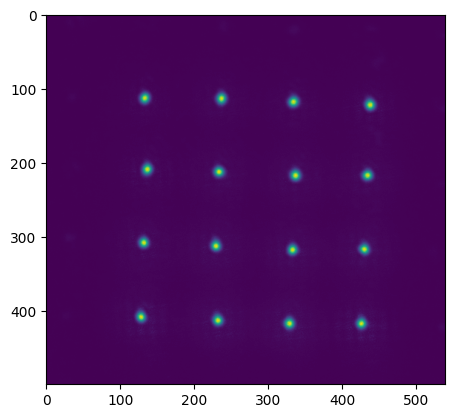

In [94]:
plt.imshow(img[100:600,900:])

In [95]:
pdf

,amplitude,centerx,centery,sigmax,sigmay,fwhmx,fwhmy,height,rsquared
0,61111.998054,83.125870,53.027190,4.694475,4.247822,11.054643,10.002857,487.745375,0.986606
1,64903.858107,79.321438,56.352922,4.924275,4.292997,11.595781,10.109235,488.638468,0.974524
2,57995.001188,78.431784,51.598405,4.508150,4.170526,10.615881,9.820837,490.932121,0.961202
3,59100.645121,78.742480,47.961862,4.703761,4.100073,11.076511,9.654934,487.725381,0.944054
4,64733.596728,83.745567,56.460650,4.933927,4.292185,11.618509,10.107323,486.495300,0.983884
5,61954.513871,82.755300,53.123805,4.456757,4.498101,10.494860,10.592218,491.863758,0.965383
6,62275.616702,82.715569,49.009809,4.766520,4.265282,11.224296,10.043971,487.516084,0.947533
7,63929.647112,83.306995,51.669136,4.754272,4.396848,11.195454,10.353784,486.739877,0.941428
8,64120.922029,88.083562,53.700680,4.638789,4.520197,10.923514,10.644251,486.695961,0.984237
9,66831.736406,87.447858,56.413246,4.833196,4.487860,11.381307,10.568103,490.375776,0.967459


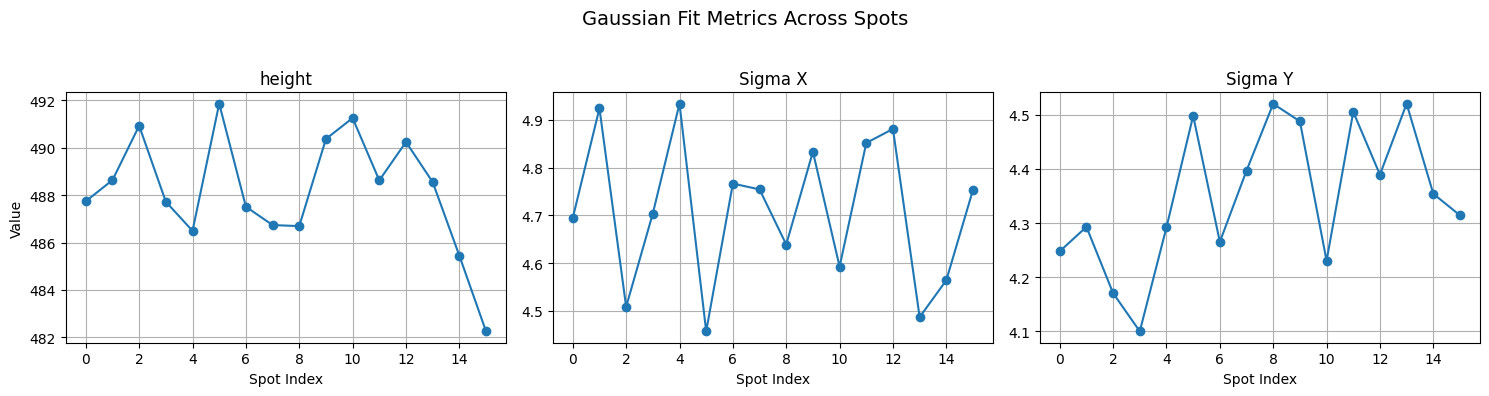

In [96]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

# Plot amplitudes
axs[0].plot(pdf.index, pdf['height'], marker='o')
axs[0].set_title("height")
axs[0].set_xlabel("Spot Index")
axs[0].set_ylabel("Value")
axs[0].grid(True)

# Plot sigmax
axs[1].plot(pdf.index, pdf['sigmax'], marker='o')
axs[1].set_title("Sigma X")
axs[1].set_xlabel("Spot Index")
axs[1].grid(True)

# Plot sigmay
axs[2].plot(pdf.index, pdf['sigmay'], marker='o')
axs[2].set_title("Sigma Y")
axs[2].set_xlabel("Spot Index")
axs[2].grid(True)

plt.suptitle("Gaussian Fit Metrics Across Spots", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [97]:
std_percent = (pdf.std() / pdf.mean()) * 100
selected = std_percent[['height','sigmax','sigmay','centerx','centery']]
styled = selected.to_frame(name='Std Dev (%)').style.set_caption("Standard Deviation as % of Mean").format(precision=2)
styled

,Std Dev (%)
height,0.50
sigmax,3.30
sigmay,3.03
centerx,4.66
centery,6.68


In [98]:
def uniformity_metric(series):
    return (series.max() - series.min()) / (series.max() + series.min())

u_height = uniformity_metric(pdf['height'])
u_sigmax = uniformity_metric(pdf['sigmax'])
u_sigmay = uniformity_metric(pdf['sigmay'])

print(f"Uniformity Metrics:")
print(f"  Height  : {u_height*100:.2f}%")
print(f"  Sigma X : {u_sigmax*100:.2f}%")
print(f"  Sigma Y : {u_sigmay*100:.2f}%")

Uniformity Metrics:
  Height  : 0.99%
  Sigma X : 5.08%
  Sigma Y : 4.88%


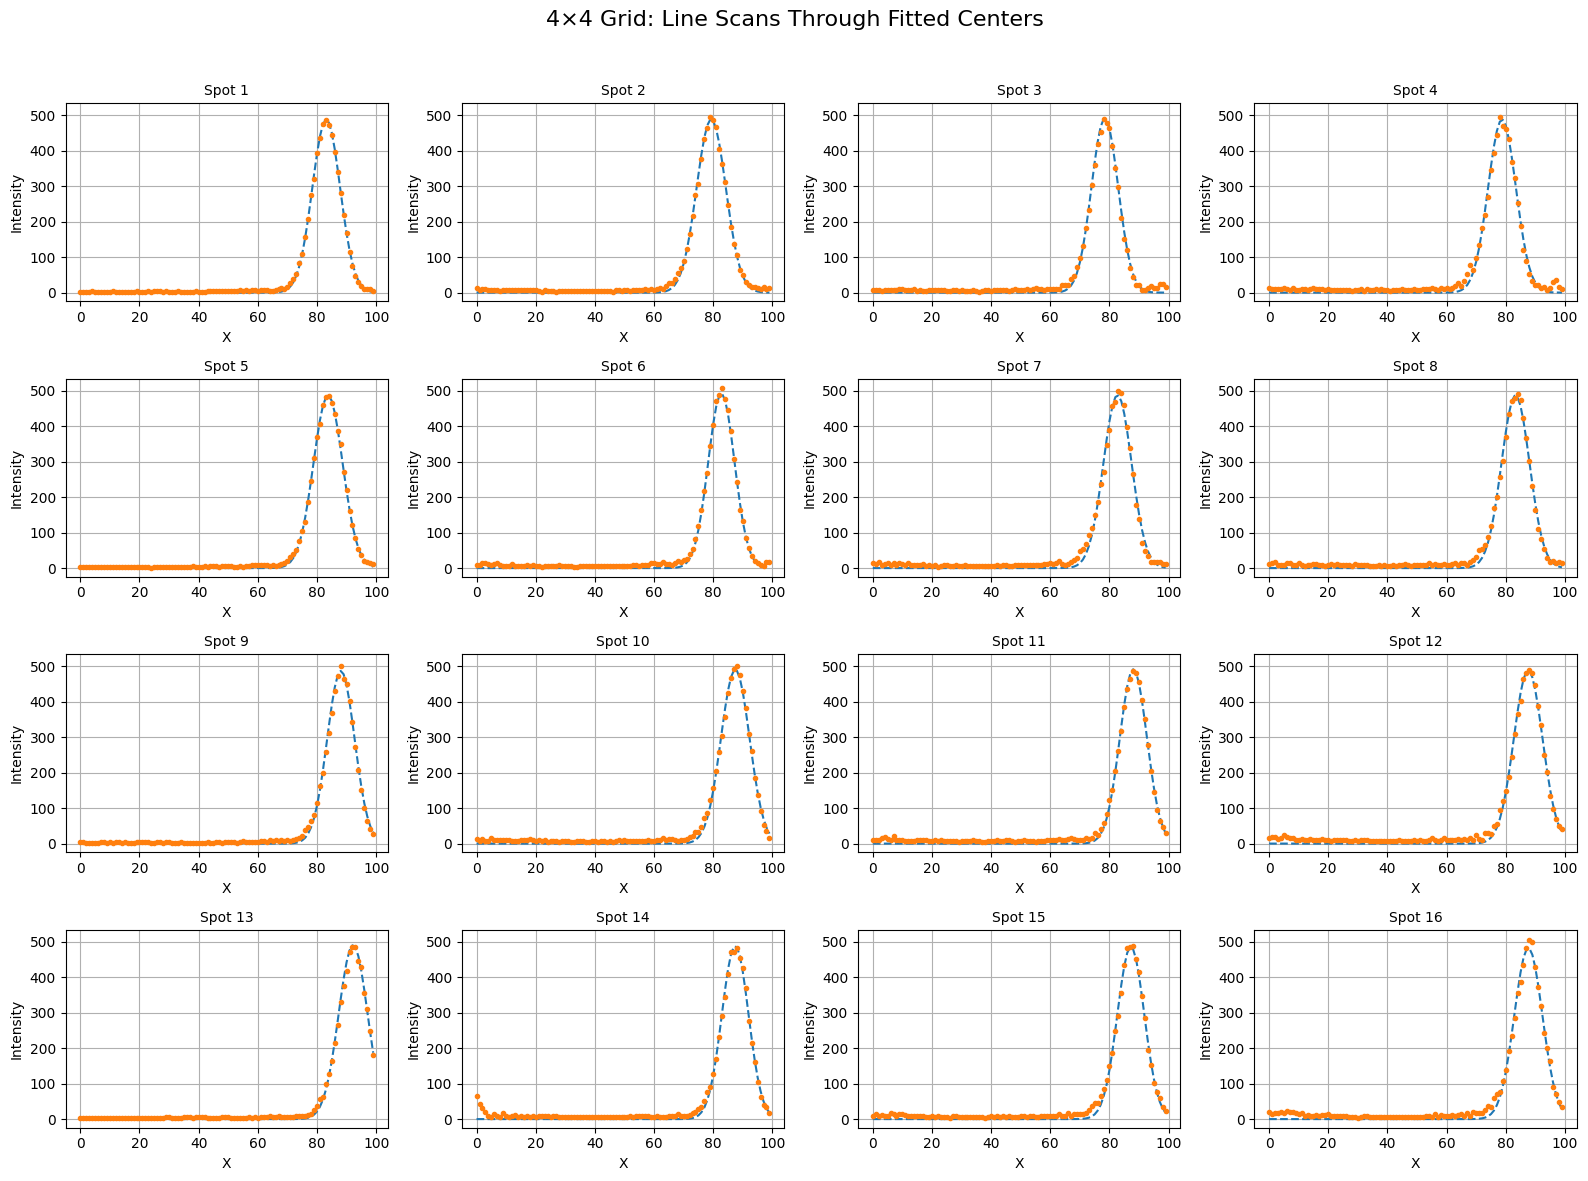

In [109]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import map_coordinates

fig, axs = plt.subplots(4, 4, figsize=(16, 12))
axs = axs.flatten()

all_lines = []

# First pass: gather all line scans for global y-limits
for idx, spot_location in enumerate(spot_locations.T):
    target = img[spot_location[1]-50:spot_location[1]+50, spot_location[0]-50:spot_location[0]+50].T
    result = results[idx]
    cx, cy = result['centerx'], result['centery']
    x_coords = np.arange(target.shape[1])
    y_coords = np.full_like(x_coords, cy)
    line_scan = map_coordinates(target, [y_coords, x_coords], order=1)
    all_lines.append(line_scan)

# Compute global y-limits for consistent scaling
all_lines_stack = np.vstack(all_lines)
ymin, ymax = all_lines_stack.min(), all_lines_stack.max()
pad = 0.05 * (ymax - ymin)
ymin -= pad
ymax += pad

# Second pass: plot
for idx, spot_location in enumerate(spot_locations.T):
    target = img[spot_location[1]-50:spot_location[1]+50, spot_location[0]-50:spot_location[0]+50].T
    result = results[idx]

    cx, cy = result['centerx'], result['centery']
    sigx, sigy = result['sigmax'], result['sigmay']
    A = result['amplitude']
    offset = result.get('offset', 0.0)

    x_coords = np.arange(target.shape[1])
    y_coords = np.full_like(x_coords, cy)
    line_scan = map_coordinates(target, [y_coords, x_coords], order=1)
    fitted_line = A / (2 * np.pi * sigx * sigy) * np.exp(-((x_coords - cx)**2) / (2 * sigx**2)) + offset

    ax = axs[idx]
    ax.plot(x_coords, fitted_line, '--', label='Fit', linewidth=1.5)
    ax.plot(x_coords, line_scan, 'o', label='Data', markersize=3)  # dots only
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"Spot {idx+1}", fontsize=10)
    ax.set_xlabel("X")
    ax.set_ylabel("Intensity")
    ax.grid(True)

plt.suptitle("4×4 Grid: Line Scans Through Fitted Centers", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
